In [1]:
!pip3 install transformers

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from transformers import GPT2LMHeadModel

C:\Users\loseu\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
model_hf = GPT2LMHeadModel.from_pretrained("gpt2")
sd_hf = model_hf.state_dict()

for k,v in sd_hf.items():
    print(k, v.shape)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 587.89it/s]

transformer.wte.weight torch.Size([50257, 768])
transformer.wpe.weight torch.Size([1024, 768])
transformer.h.0.ln_1.weight torch.Size([768])
transformer.h.0.ln_1.bias torch.Size([768])
transformer.h.0.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.0.attn.c_attn.bias torch.Size([2304])
transformer.h.0.attn.c_proj.weight torch.Size([768, 768])
transformer.h.0.attn.c_proj.bias torch.Size([768])
transformer.h.0.ln_2.weight torch.Size([768])
transformer.h.0.ln_2.bias torch.Size([768])
transformer.h.0.mlp.c_fc.weight torch.Size([768, 3072])
transformer.h.0.mlp.c_fc.bias torch.Size([3072])
transformer.h.0.mlp.c_proj.weight torch.Size([3072, 768])
transformer.h.0.mlp.c_proj.bias torch.Size([768])
transformer.h.1.ln_1.weight torch.Size([768])
transformer.h.1.ln_1.bias torch.Size([768])
transformer.h.1.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.1.attn.c_attn.bias torch.Size([2304])
transformer.h.1.attn.c_proj.weight torch.Size([768, 768])
transformer.h.1.attn.c_proj.bias 

### Weight sizes

```json
transformer.wte.weight torch.Size([50257, 768])
transformer.wpe.weight torch.Size([1024, 768])
transformer.h.0.ln_1.weight torch.Size([768])
transformer.h.0.ln_1.bias torch.Size([768])
transformer.h.0.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.0.attn.c_attn.bias torch.Size([2304])
transformer.h.0.attn.c_proj.weight torch.Size([768, 768])
transformer.h.0.attn.c_proj.bias torch.Size([768])
transformer.h.0.ln_2.weight torch.Size([768])
transformer.h.0.ln_2.bias torch.Size([768])
transformer.h.0.mlp.c_fc.weight torch.Size([768, 3072])
transformer.h.0.mlp.c_fc.bias torch.Size([3072])
transformer.h.0.mlp.c_proj.weight torch.Size([3072, 768])
transformer.h.0.mlp.c_proj.bias torch.Size([768])
transformer.h.1.ln_1.weight torch.Size([768])
transformer.h.1.ln_1.bias torch.Size([768])
transformer.h.1.attn.c_attn.weight torch.Size([768, 2304])
transformer.h.1.attn.c_attn.bias torch.Size([2304])
transformer.h.1.attn.c_proj.weight torch.Size([768, 768])
transformer.h.1.attn.c_proj.bias torch.Size([768])
transformer.h.1.ln_2.weight torch.Size([768])
transformer.h.1.ln_2.bias torch.Size([768])
transformer.h.1.mlp.c_fc.weight torch.Size([768, 3072])
transformer.h.1.mlp.c_fc.bias torch.Size([3072])
transformer.h.1.mlp.c_proj.weight torch.Size([3072, 768])
...
transformer.h.11.mlp.c_proj.bias torch.Size([768])
transformer.ln_f.weight torch.Size([768])
transformer.ln_f.bias torch.Size([768])
lm_head.weight torch.Size([50257, 768])
```

In [4]:
sd_hf['transformer.wte.weight'][1, :20]

tensor([ 0.0403, -0.0486,  0.0462, -0.0990,  0.0826,  0.0768, -0.2202, -0.0110,
         0.0592,  0.0354,  0.0397,  0.0233,  0.1021, -0.1099,  0.0387,  0.0378,
         0.1335, -0.0711,  0.0218,  0.2361])

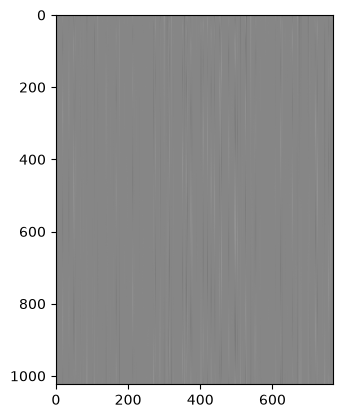

In [5]:
import matplotlib.pyplot as plt
%matplotlib inline

plt.imshow(sd_hf['transformer.wpe.weight'], cmap='gray')

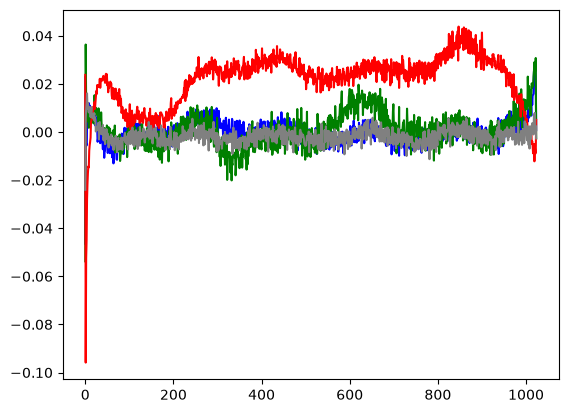

In [6]:
plt.plot(sd_hf['transformer.wpe.weight'][:, 150], color='blue')
plt.plot(sd_hf['transformer.wpe.weight'][:, 200], color='green')
plt.plot(sd_hf['transformer.wpe.weight'][:, 250], color='red')
plt.plot(sd_hf['transformer.wpe.weight'][:, 400], color='gray')

### Positional Embedding tablosundaki dalgalanma sebebi

Transformer mimarisinde Sinüzoidal encoding kullanılır yani pozisyonlar sinüs ve kosinüs ile hesaplanır.
GPT-2 de position embedding yani öğrenilebilir parametreler kullanılır. bunlar da dalgalanma yaratabilir eğitimden sonra.

In [7]:
wpe = sd_hf["transformer.wpe.weight"]

print("Minimum:", wpe.min().item())
print("Maximum:", wpe.max().item())
print("Mean:", wpe.mean().item())
print("Std:", wpe.std().item())

Minimum: -4.538113594055176
Maximum: 4.065310955047607
Mean: -0.0006787169259041548
Std: 0.1226913258433342


In [8]:
import torch
import torch.nn as nn

In [9]:
position_embedding_table = nn.Embedding(1024, 768)

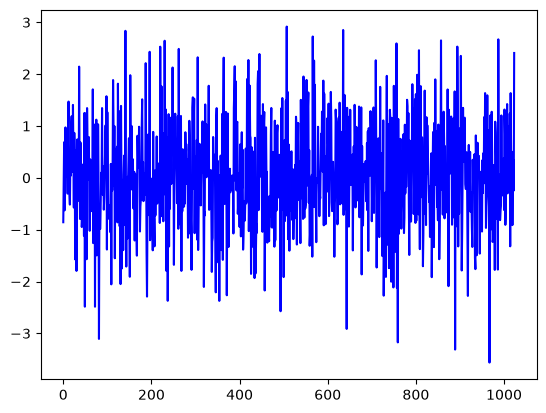

In [10]:
plt.plot(
    position_embedding_table.weight[:, 150].detach().numpy(),
    color='blue'
)

In [11]:
x_t = torch.randn((30, 30, 30))
q, k, v = x_t.split(10, 2)

q.shape

torch.Size([30, 30, 10])

In [12]:
from transformers import pipeline, set_seed

generator = pipeline('text-generation', model='gpt2')
set_seed(42)
generator("Hello, I'm a language model,", max_length=40, num_return_sequences=5)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 307.61it/s]


[{'generated_text': "Hello, I'm a language model, so you can't just use the same data model and just use different languages. There's a lot of overlap between languages because there are so many different languages."},
 {'generated_text': "Hello, I'm a language model, you know.\n\nThat's right…\n\nIf you read about it, you'll understand how I've written this.\n\nIn this article,"},
 {'generated_text': "Hello, I'm a language model, I'm a computer science professor at the University of Oregon. I'm going to talk about AI. I'm going to talk about computer vision in the context of"},
 {'generated_text': "Hello, I'm a language model, I'm a model of a language, and I'm a model of a language. I've got a model for a language, and I've got a model"},
 {'generated_text': "Hello, I'm a language model, and I have a lot of ideas for future projects. I like to think of it as a very deep language, and I think of it as an expressive language"}]

In [23]:
idx = torch.tensor([[0, 1, 2, 3, 4]], dtype=torch.long)
logits = model_hf(idx)

logits

CausalLMOutputWithCrossAttentions(loss=None, logits=tensor([[[-37.7550, -38.2652, -40.4860,  ..., -47.3888, -46.8042, -36.8606],
         [-69.7059, -68.8304, -68.4345,  ..., -75.0572, -74.2558, -64.0604],
         [-50.3636, -47.9540, -51.2161,  ..., -63.0638, -60.9918, -52.0684],
         [-67.1389, -66.1321, -64.8171,  ..., -80.9309, -77.7805, -70.2395],
         [-71.4395, -71.6656, -67.7697,  ..., -85.0580, -82.6441, -74.0991]]],
       grad_fn=<UnsafeViewBackward0>), past_key_values=DynamicCache(layers=[DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer, DynamicLayer]), hidden_states=None, attentions=None, cross_attentions=None)